<a href="https://colab.research.google.com/github/Aiipppxy/NEURAL-NETWORK/blob/main/Muhammad_Arifin_Test4_Analisis_Sentimen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Analisis Sentimen — Topik: Kualitas Udara (Google Colab)
Neural Network (MLP) + TF-IDF



Persiapan library

In [16]:
%pip install -q wordcloud streamlit

import os, re, sys, shutil, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
os.makedirs("hasil", exist_ok=True)

# Cek Node.js (dibutuhkan untuk crawling)
if shutil.which("node") is None:
    subprocess.run("apt-get -qq install -y nodejs npm", shell=True)
print("Node.js:", subprocess.run(["node", "-v"], capture_output=True, text=True).stdout.strip())
print("Library siap. Folder kerja:", os.getcwd())

Node.js: v22.23.4
Library siap. Folder kerja: /content


## 1.a - Crawling Twitter/X

In [17]:
import glob

def ambil_token():
    try:
        from google.colab import userdata
        return userdata.get("AUTH_TOKEN") or ""
    except Exception:
        pass
    return open("token.txt").read().strip() if os.path.exists("token.txt") else ""

AUTH_TOKEN = ambil_token()
KEYWORDS = ["kualitas udara lang:id", "polusi udara lang:id", "kabut asap lang:id"]
LIMIT = 200              # tweet per kata kunci
FORCE_CRAWLING = False   # True = crawling ulang walau tweet_data.csv sudah ada

if not AUTH_TOKEN:
    print("Token tidak ditemukan -> lewati crawling, gunakan Cell 1b (upload tweet_data.csv).")
elif os.path.exists("tweet_data.csv") and not FORCE_CRAWLING:
    print("tweet_data.csv sudah ada -> crawling dilewati.")
else:
    # Browser (Chromium) untuk tweet-harvest
    subprocess.run("npx -y playwright install --with-deps chromium", shell=True)
    for i, kw in enumerate(KEYWORDS):
        print(f"\n=== Crawling: {kw} ===")
        subprocess.run(["npx", "-y", "tweet-harvest@latest", "-o", f"kw_{i}.csv",
                        "-s", kw, "--tab", "LATEST", "-l", str(LIMIT), "--token", AUTH_TOKEN])
    files_csv = glob.glob("tweets-data/kw_*.csv")
    if files_csv:
        g = pd.concat([pd.read_csv(f) for f in files_csv], ignore_index=True)
        g = g[["created_at", "username", "full_text"]].dropna(subset=["full_text"])
        g = g.drop_duplicates(subset="full_text")
        g.to_csv("tweet_data.csv", index=False)
        print(f"\nBerhasil: {len(g)} tweet disimpan ke tweet_data.csv")
    else:
        print("\nCrawling tidak menghasilkan file. Gunakan Cell 1b (upload tweet_data.csv).")

tweet_data.csv sudah ada -> crawling dilewati.


## 1.b — Upload tweet_data.csv

In [18]:
if os.path.exists("tweet_data.csv"):
    print("tweet_data.csv sudah ada, upload tidak diperlukan.")
else:
    from google.colab import files
    up = files.upload()          # pilih file tweet_data.csv
    for nama in up:
        if nama != "tweet_data.csv":
            os.replace(nama, "tweet_data.csv")
    print("Tersimpan:", os.path.exists("tweet_data.csv"))

tweet_data.csv sudah ada, upload tidak diperlukan.


##1.c — Muat & validasi data

In [19]:
df = pd.read_csv("tweet_data.csv")
wajib = {"created_at", "username", "full_text"}
assert wajib.issubset(df.columns), f"Kolom wajib kurang: {wajib - set(df.columns)}"
df = df[["created_at", "username", "full_text"]].dropna(subset=["full_text"])
df = df.drop_duplicates(subset="full_text").reset_index(drop=True)
print(f"Jumlah tweet: {len(df)}", "(OK >= 300)" if len(df) >= 300 else "(KURANG dari 300!)")
df.head()

Jumlah tweet: 453 (OK >= 300)


,created_at,username,full_text
0,2026-10-13T13:43:53.000Z,PutriKariimah,Kebakaran Hutan Kalimantan: Petugas Pemadam Ap...
1,2026-10-13T13:34:21.000Z,xcordeirro,di tempat gw asap sampai warna kuning dan kual...
2,2026-10-13T13:25:56.000Z,rinnatto_,"@aldapstsr Bener kokk, ini kualitas udara td s..."
3,2026-10-13T09:49:55.000Z,kompascom,Kabut asap tebal menyelimuti Kota Palangka Ray...
4,2026-10-13T09:33:35.000Z,kompascom,Kabut asap di Singapura masih berlanjut dengan...


## 2. File dashboard Streamlit


In [20]:
%%writefile app_sentimen_nn.py
"""
Dashboard Analisis Sentimen - Topik: Kualitas Udara
Model: Neural Network (MLPClassifier) + TF-IDF
Jalankan: streamlit run app_sentimen_nn.py
"""
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

st.set_page_config(page_title="Sentimen Kualitas Udara", page_icon="🌫️", layout="wide")

# ---------------------------------------------------------------------------
# KONFIGURASI
# ---------------------------------------------------------------------------
LABELS = ["positif", "netral", "negatif"]
COLORS = {"positif": "#2e9e5b", "netral": "#7f8c8d", "negatif": "#d64545"}
CMAPS = {"positif": "Greens", "netral": "Greys", "negatif": "Reds"}
EMOJI = {"positif": "😊", "netral": "😐", "negatif": "😠"}

# Lexicon sederhana untuk topik kualitas udara (silakan tambah / sesuaikan)
KATA_POSITIF = {
    "aman", "lega", "selamat", "bantuan", "pulih", "bersih", "segar", "sehat",
    "baik", "membaik", "turun", "cerah", "sejuk", "nyaman", "bagus", "optimis",
    "hijau", "mendukung", "berhasil", "terkendali", "hujan", "lancar", "syukur",
}
KATA_NEGATIF = {
    "polusi", "parah", "buruk", "bahaya", "berbahaya", "kabut", "asap", "tercemar",
    "sesak", "batuk", "ispa", "sakit", "kotor", "pekat", "macet", "rusak",
    "menyesakkan", "gangguan", "naik", "tidak", "sehat", "mengkhawatirkan", "korban",
    "lelah", "mengganggu", "pengap", "debu", "kebakaran",
}
# "sehat" dan "tidak" muncul di dua daftar -> dibersihkan di bawah agar tidak ambigu
KATA_NEGATIF -= {"sehat", "tidak"}

STOPWORDS = {
    "yang", "dan", "di", "ke", "dari", "ini", "itu", "dengan", "untuk", "pada",
    "adalah", "juga", "karena", "ada", "saya", "kita", "kami", "akan", "sudah",
    "udah", "lagi", "nya", "aja", "sih", "dong", "deh", "ya", "yg", "dgn", "utk",
    "tdk", "gak", "ga", "nggak", "atau", "oleh", "dalam", "sangat", "banget",
    "si", "para", "kok", "pun", "jadi", "bisa", "mau", "ke", "se", "rt",
}


# ---------------------------------------------------------------------------
# FUNGSI PEMROSESAN
# ---------------------------------------------------------------------------
def clean_text(text: str) -> str:
    """Cleansing: hapus URL, mention, hashtag, angka, simbol; case folding; rapikan spasi."""
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)      # URL
    text = re.sub(r"@\w+", " ", text)                  # mention
    text = re.sub(r"#\w+", " ", text)                  # hashtag
    text = re.sub(r"[^A-Za-z\s]", " ", text)           # simbol, angka, emoji
    text = text.lower()                                # case folding
    text = re.sub(r"\s+", " ", text).strip()           # spasi berlebih
    return text


def label_sentiment(text: str) -> str:
    """Pelabelan rule-based berdasarkan jumlah kata positif vs negatif."""
    tokens = text.split()
    pos = sum(t in KATA_POSITIF for t in tokens)
    neg = sum(t in KATA_NEGATIF for t in tokens)
    if pos > neg:
        return "positif"
    if neg > pos:
        return "negatif"
    return "netral"


@st.cache_data(show_spinner=False)
def load_and_prepare(file) -> pd.DataFrame:
    df = pd.read_csv(file)
    needed = {"created_at", "username", "full_text"}
    missing = needed - set(df.columns)
    if missing:
        raise ValueError(f"Kolom wajib tidak ditemukan: {', '.join(sorted(missing))}")
    df = df[["created_at", "username", "full_text"]].dropna(subset=["full_text"]).copy()
    df = df.drop_duplicates(subset="full_text").reset_index(drop=True)
    df["clean_text"] = df["full_text"].apply(clean_text)
    df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)
    df["sentimen"] = df["clean_text"].apply(label_sentiment)
    return df


@st.cache_resource(show_spinner=False)
def train_model(texts: tuple, labels: tuple, hidden: int, max_iter: int, test_size: float):
    X_text = pd.Series(texts)
    y = pd.Series(labels)
    strat = y if y.value_counts().min() >= 2 else None
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_text, y, test_size=test_size, random_state=42, stratify=strat
    )
    tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
    Xtr = tfidf.fit_transform(X_tr)
    Xte = tfidf.transform(X_te)
    mlp = MLPClassifier(
        hidden_layer_sizes=(hidden,), activation="relu", solver="adam",
        max_iter=max_iter, random_state=42, early_stopping=False,
    )
    mlp.fit(Xtr, y_tr)
    pred = mlp.predict(Xte)
    return tfidf, mlp, y_te.tolist(), pred.tolist()


def make_wordcloud(text: str, sentiment: str):
    words = " ".join(w for w in text.split() if w not in STOPWORDS and len(w) > 2)
    if not words.strip():
        return None
    return WordCloud(width=700, height=400, background_color="white",
                     colormap=CMAPS[sentiment], max_words=100).generate(words)


# ---------------------------------------------------------------------------
# SIDEBAR
# ---------------------------------------------------------------------------
st.title("🌫️ Analisis Sentimen Kualitas Udara")
st.caption("Neural Network (MLP) + TF-IDF • Data: Twitter/X")

with st.sidebar:
    st.header("⚙️ Pengaturan")
    up = st.file_uploader("Upload CSV (opsional)", type="csv")
    st.caption("Jika kosong, aplikasi memakai `tweet_data.csv` di folder yang sama.")
    hidden = st.number_input("Neuron hidden layer", 10, 500, 100, step=10)
    max_iter = st.slider("Max iterasi", 100, 1000, 500, step=50)
    test_size = st.slider("Porsi data uji", 0.1, 0.4, 0.2, step=0.05)

try:
    df = load_and_prepare(up if up is not None else "tweet_data.csv")
except FileNotFoundError:
    st.error("File `tweet_data.csv` tidak ditemukan. Letakkan di folder yang sama atau upload lewat sidebar.")
    st.stop()
except ValueError as e:
    st.error(str(e))
    st.stop()

if len(df) < 20:
    st.warning("Data terlalu sedikit untuk melatih model (minimal puluhan tweet).")
    st.stop()

tab1, tab2, tab3, tab4, tab5 = st.tabs(
    ["📄 Data", "📊 Distribusi", "☁️ WordCloud", "🧠 Model & Evaluasi", "🔮 Prediksi"]
)

# ---------------------------------------------------------------------------
# TAB 1: DATA
# ---------------------------------------------------------------------------
with tab1:
    c1, c2, c3 = st.columns(3)
    c1.metric("Jumlah tweet", len(df))
    c2.metric("Jumlah pengguna unik", df["username"].nunique())
    c3.metric("Jumlah fitur (kolom)", df.shape[1])
    st.subheader("Cuplikan data hasil cleansing & pelabelan")
    st.dataframe(df[["created_at", "username", "full_text", "clean_text", "sentimen"]],
                 width="stretch", height=380)
    st.download_button("⬇️ Unduh data berlabel", df.to_csv(index=False).encode("utf-8"),
                       "tweet_berlabel.csv", "text/csv")

# ---------------------------------------------------------------------------
# TAB 2: DISTRIBUSI
# ---------------------------------------------------------------------------
with tab2:
    counts = df["sentimen"].value_counts().reindex(LABELS).fillna(0).astype(int)
    st.subheader("Distribusi Sentimen")
    cols = st.columns(3)
    for col, lab in zip(cols, LABELS):
        col.metric(f"{EMOJI[lab]} {lab.capitalize()}", int(counts[lab]),
                   f"{counts[lab] / counts.sum():.1%}", delta_color="off")

    left, right = st.columns(2)
    with left:
        fig, ax = plt.subplots(figsize=(5, 4))
        bars = ax.bar(counts.index, counts.values, color=[COLORS[l] for l in counts.index])
        ax.bar_label(bars)
        ax.set_ylabel("Jumlah tweet")
        ax.set_title("Diagram Batang")
        st.pyplot(fig)
    with right:
        fig, ax = plt.subplots(figsize=(5, 4))
        ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
               colors=[COLORS[l] for l in counts.index])
        ax.set_title("Diagram Lingkaran")
        st.pyplot(fig)

# ---------------------------------------------------------------------------
# TAB 3: WORDCLOUD
# ---------------------------------------------------------------------------
with tab3:
    st.subheader("WordCloud per Sentimen")
    cols = st.columns(3)
    for col, lab in zip(cols, LABELS):
        with col:
            st.markdown(f"**{EMOJI[lab]} {lab.capitalize()}**")
            wc = make_wordcloud(" ".join(df.loc[df["sentimen"] == lab, "clean_text"]), lab)
            if wc is None:
                st.info("Tidak ada data.")
            else:
                fig, ax = plt.subplots(figsize=(5, 3))
                ax.imshow(wc, interpolation="bilinear")
                ax.axis("off")
                st.pyplot(fig)

# ---------------------------------------------------------------------------
# TAB 4: MODEL & EVALUASI
# ---------------------------------------------------------------------------
with tab4:
    with st.spinner("Melatih Neural Network..."):
        tfidf, mlp, y_true, y_pred = train_model(
            tuple(df["clean_text"]), tuple(df["sentimen"]), int(hidden), int(max_iter), float(test_size)
        )

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    st.subheader("Metrik Performa (rata-rata weighted)")
    m1, m2, m3, m4 = st.columns(4)
    m1.metric("Akurasi", f"{acc:.4f}")
    m2.metric("Presisi", f"{prec:.4f}")
    m3.metric("Recall", f"{rec:.4f}")
    m4.metric("F1-Score", f"{f1:.4f}")

    st.caption(f"Data latih: {int(len(df) * (1 - test_size))} • Data uji: {len(y_true)} "
               f"• Arsitektur: TF-IDF → Dense({int(hidden)}, ReLU) → Softmax • Optimizer: Adam")

    present = [l for l in LABELS if l in set(y_true) | set(y_pred)]
    rep = pd.DataFrame(classification_report(y_true, y_pred, labels=present,
                                             output_dict=True, zero_division=0)).T.round(4)
    left, right = st.columns(2)
    with left:
        st.markdown("**Tabel evaluasi per kelas**")
        st.dataframe(rep, width="stretch")
        st.markdown("**Grafik metrik per kelas**")
        per = rep.loc[present, ["precision", "recall", "f1-score"]]
        fig, ax = plt.subplots(figsize=(5, 3.5))
        per.plot(kind="bar", ax=ax, rot=0)
        ax.set_ylim(0, 1.05)
        ax.legend(loc="lower right")
        st.pyplot(fig)
    with right:
        st.markdown("**Confusion Matrix**")
        cm = confusion_matrix(y_true, y_pred, labels=present)
        fig, ax = plt.subplots(figsize=(5, 4.2))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=present,
                    yticklabels=present, ax=ax)
        ax.set_xlabel("Prediksi")
        ax.set_ylabel("Aktual")
        st.pyplot(fig)

    if hasattr(mlp, "loss_curve_"):
        st.markdown("**Kurva loss selama pelatihan**")
        fig, ax = plt.subplots(figsize=(8, 2.8))
        ax.plot(mlp.loss_curve_)
        ax.set_xlabel("Iterasi")
        ax.set_ylabel("Loss")
        st.pyplot(fig)

# ---------------------------------------------------------------------------
# TAB 5: PREDIKSI
# ---------------------------------------------------------------------------
with tab5:
    st.subheader("Prediksi Sentimen Teks Baru")
    teks = st.text_area("Masukkan teks:", placeholder="contoh: udara hari ini sangat buruk, kabut asap pekat sekali")
    if st.button("Prediksi", type="primary"):
        bersih = clean_text(teks)
        if not bersih:
            st.warning("Teks kosong atau tidak mengandung huruf setelah dibersihkan.")
        else:
            vec = tfidf.transform([bersih])
            pred = mlp.predict(vec)[0]
            proba = mlp.predict_proba(vec)[0]
            st.markdown(f"**Teks bersih:** `{bersih}`")
            st.markdown(f"## {EMOJI[pred]} Sentimen: **{pred.upper()}**")
            prob_df = pd.DataFrame({"Sentimen": mlp.classes_, "Probabilitas": proba})
            prob_df["Probabilitas (%)"] = (prob_df["Probabilitas"] * 100).round(2)
            c1, c2 = st.columns([1, 2])
            with c1:
                st.dataframe(prob_df[["Sentimen", "Probabilitas (%)"]], hide_index=True)
            with c2:
                fig, ax = plt.subplots(figsize=(5, 2.5))
                ax.barh(prob_df["Sentimen"], prob_df["Probabilitas"],
                        color=[COLORS[s] for s in prob_df["Sentimen"]])
                ax.set_xlim(0, 1)
                st.pyplot(fig)


Overwriting app_sentimen_nn.py


## 3. Pemrosesan Teks

In [21]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # URL
    text = re.sub(r"@\w+", " ", text)               # mention
    text = re.sub(r"#\w+", " ", text)               # hashtag
    text = re.sub(r"[^A-Za-z\s]", " ", text)        # simbol, angka, emoji
    text = text.lower()                              # case folding
    return re.sub(r"\s+", " ", text).strip()         # spasi berlebih

df["clean_text"] = df["full_text"].apply(clean_text)
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)
df[["full_text", "clean_text"]].head(10)

,full_text,clean_text
0,Kebakaran Hutan Kalimantan: Petugas Pemadam Ap...,kebakaran hutan kalimantan petugas pemadam api...
1,di tempat gw asap sampai warna kuning dan kual...,di tempat gw asap sampai warna kuning dan kual...
2,"@aldapstsr Bener kokk, ini kualitas udara td s...",bener kokk ini kualitas udara td siang
3,Kabut asap tebal menyelimuti Kota Palangka Ray...,kabut asap tebal menyelimuti kota palangka ray...
4,Kabut asap di Singapura masih berlanjut dengan...,kabut asap di singapura masih berlanjut dengan...
5,🇸🇦| Kedatangan Bala Bantuan dari Koalisi Saudi...,kedatangan bala bantuan dari koalisi saudi ke ...
6,"Halo, Sobat BMKG!\nPemantauan PM2.5 dilakukan ...",halo sobat bmkg pemantauan pm dilakukan untuk ...
7,"Scroll berita, kepala langsung ruwet. \n\nGaus...",scroll berita kepala langsung ruwet gausah jau...
8,@03__nakula Presiden dan wakil presiden TIDAK ...,presiden dan wakil presiden tidak kapabel meng...
9,Outfit kerja hari ini disesuikan dengan kondis...,outfit kerja hari ini disesuikan dengan kondis...


## 4. Pelabelan Sentimen (Rule-Based)

In [22]:
KATA_POSITIF = {"aman","lega","selamat","bantuan","pulih","bersih","segar","sehat","baik",
    "membaik","turun","cerah","sejuk","nyaman","bagus","optimis","hijau","mendukung",
    "berhasil","terkendali","hujan","lancar","syukur","alhamdulillah","indah","tenang"}
KATA_NEGATIF = {"polusi","parah","buruk","bahaya","berbahaya","kabut","asap","tercemar",
    "sesak","batuk","ispa","sakit","kotor","pekat","macet","rusak","menyesakkan",
    "gangguan","naik","mengkhawatirkan","korban","mengganggu","pengap","debu",
    "kebakaran","muak","capek","parahnya","menderita","tebal"}

def label_sentiment(text):
    tokens = text.split()
    pos = sum(t in KATA_POSITIF for t in tokens)
    neg = sum(t in KATA_NEGATIF for t in tokens)
    if pos > neg: return "positif"
    if neg > pos: return "negatif"
    return "netral"

df["sentimen"] = df["clean_text"].apply(label_sentiment)
df[["clean_text", "sentimen"]].head(10)

,clean_text,sentimen
0,kebakaran hutan kalimantan petugas pemadam api...,negatif
1,di tempat gw asap sampai warna kuning dan kual...,negatif
2,bener kokk ini kualitas udara td siang,netral
3,kabut asap tebal menyelimuti kota palangka ray...,negatif
4,kabut asap di singapura masih berlanjut dengan...,negatif
5,kedatangan bala bantuan dari koalisi saudi ke ...,positif
6,halo sobat bmkg pemantauan pm dilakukan untuk ...,positif
7,scroll berita kepala langsung ruwet gausah jau...,positif
8,presiden dan wakil presiden tidak kapabel meng...,positif
9,outfit kerja hari ini disesuikan dengan kondis...,netral


## 5. Analisis Distribusi Sentimen

sentimen
positif     26
netral      61
negatif    366
Name: count, dtype: int64 

sentimen
positif     5.7 %
netral     13.5 %
negatif    80.8 %
Name: count, dtype: object


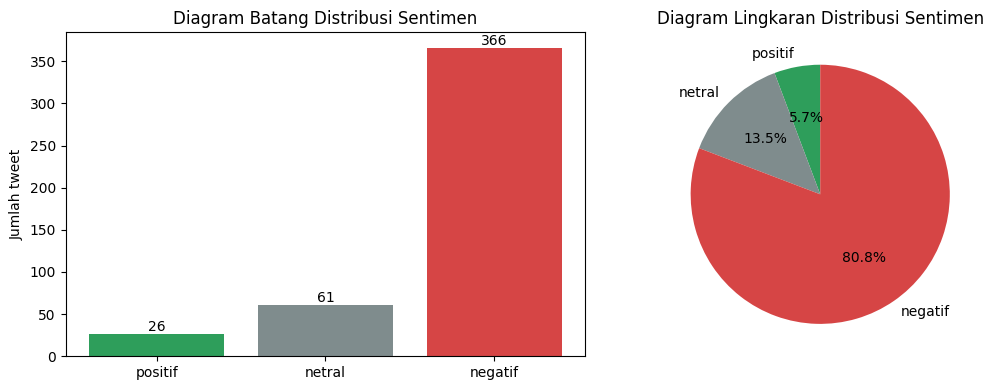

In [23]:
LABELS = ["positif", "netral", "negatif"]
WARNA  = {"positif": "#2e9e5b", "netral": "#7f8c8d", "negatif": "#d64545"}
counts = df["sentimen"].value_counts().reindex(LABELS).fillna(0).astype(int)
print(counts, "\n")
print((counts / counts.sum() * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bars = ax[0].bar(counts.index, counts.values, color=[WARNA[l] for l in counts.index])
ax[0].bar_label(bars); ax[0].set_title("Diagram Batang Distribusi Sentimen"); ax[0].set_ylabel("Jumlah tweet")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
          colors=[WARNA[l] for l in counts.index])
ax[1].set_title("Diagram Lingkaran Distribusi Sentimen")
plt.tight_layout(); plt.savefig("hasil/01_distribusi_sentimen.png", dpi=150); plt.show()

## 6. Visualisasi WordCloud

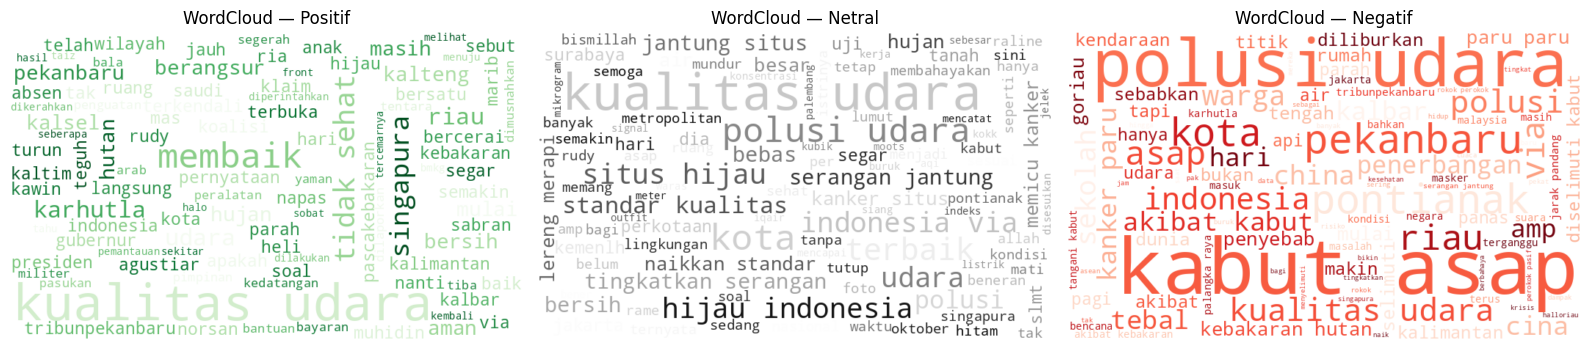

In [24]:
STOP = {"yang","dan","di","ke","dari","ini","itu","dengan","untuk","pada","adalah","juga",
        "karena","ada","saya","kita","kami","akan","sudah","udah","lagi","nya","aja","sih",
        "dong","deh","ya","yg","dgn","utk","tdk","gak","ga","nggak","atau","oleh","dalam",
        "sangat","banget","kok","pun","jadi","bisa","mau","rt"}
CMAP = {"positif": "Greens", "netral": "Greys", "negatif": "Reds"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, lab in zip(axes, LABELS):
    teks = " ".join(w for w in " ".join(df.loc[df["sentimen"] == lab, "clean_text"]).split()
                    if w not in STOP and len(w) > 2)
    ax.axis("off"); ax.set_title(f"WordCloud — {lab.capitalize()}")
    if teks.strip():
        wc = WordCloud(width=700, height=420, background_color="white",
                       colormap=CMAP[lab], max_words=100).generate(teks)
        ax.imshow(wc, interpolation="bilinear")
plt.tight_layout(); plt.savefig("hasil/02_wordcloud.png", dpi=150); plt.show()

## 7. Pembuatan Model Neural Network

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["sentimen"], test_size=0.2, random_state=42,
    stratify=df["sentimen"] if df["sentimen"].value_counts().min() >= 2 else None)

tfidf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, max_features=5000)
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)
print(f"Data latih: {Xtr.shape[0]} | Data uji: {Xte.shape[0]} | Fitur TF-IDF: {Xtr.shape[1]}")

def buat_model(hidden=100, alpha=1e-4):
    return MLPClassifier(hidden_layer_sizes=(hidden,), activation="relu", solver="adam",
                         alpha=alpha, max_iter=500, random_state=42)

kandidat = [(100, 1e-4), (100, 1e-3), (200, 1e-4), (64, 1e-3)]   # (neuron, alpha)
skor = {}
for h, a in kandidat:
    skor[(h, a)] = cross_val_score(buat_model(h, a), Xtr, y_train, cv=3, scoring="accuracy").mean()
    print(f"hidden={h:<4} alpha={a:<7} CV akurasi = {skor[(h, a)]:.4f}")

dasar = kandidat[0]
terbaik = dasar if skor[dasar] >= 0.70 else max(skor, key=skor.get)
print(f"\nKonfigurasi dipakai: hidden={terbaik[0]}, alpha={terbaik[1]}")

model = buat_model(*terbaik).fit(Xtr, y_train)
y_pred = model.predict(Xte)
print("Model selesai dilatih.")

Data latih: 362 | Data uji: 91 | Fitur TF-IDF: 4722
hidden=100  alpha=0.0001  CV akurasi = 0.8785
hidden=100  alpha=0.001   CV akurasi = 0.8785
hidden=200  alpha=0.0001  CV akurasi = 0.8785
hidden=64   alpha=0.001   CV akurasi = 0.8812

Konfigurasi dipakai: hidden=100, alpha=0.0001
Model selesai dilatih.


## 8. Evaluasi Model

,Metrik,Nilai,Persen
0,Akurasi,0.912088,91.21 %
1,Presisi,0.900913,90.09 %
2,Recall,0.912088,91.21 %
3,F1-Score,0.901997,90.2 %


STATUS: ✅ Akurasi >= 70%

               precision    recall  f1-score   support

     positif       0.67      0.40      0.50         5
      netral       0.78      0.58      0.67        12
     negatif       0.94      1.00      0.97        74

    accuracy                           0.91        91
   macro avg       0.79      0.66      0.71        91
weighted avg       0.90      0.91      0.90        91



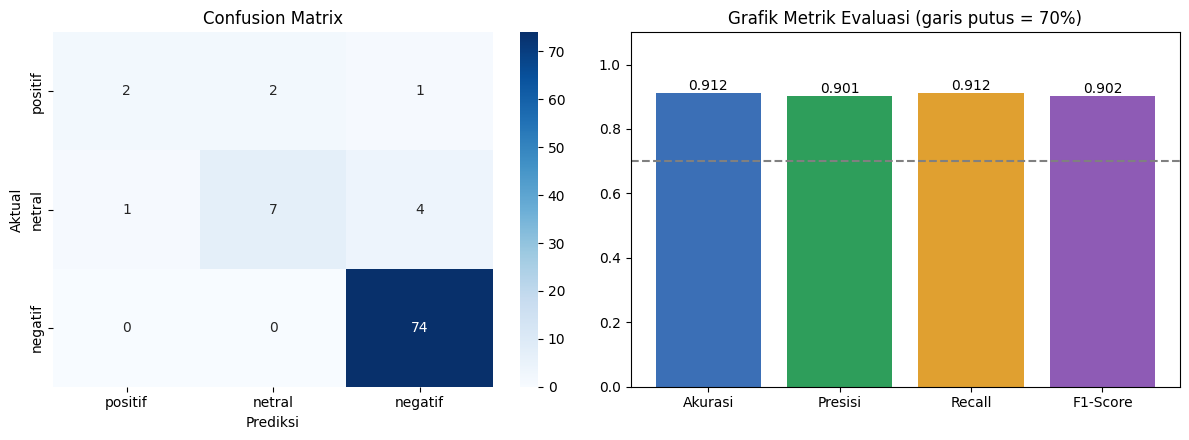

In [26]:
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
rec  = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1   = f1_score(y_test, y_pred, average="weighted", zero_division=0)

hasil = pd.DataFrame({"Metrik": ["Akurasi", "Presisi", "Recall", "F1-Score"],
                      "Nilai": [acc, prec, rec, f1]})
hasil["Persen"] = (hasil["Nilai"] * 100).round(2).astype(str) + " %"
display(hasil)
print("STATUS:", "✅ Akurasi >= 70%" if acc >= 0.70 else "⚠️ Akurasi < 70% — perluas kata di Cell 4 / tambah data")

present = [l for l in LABELS if l in set(y_test) | set(y_pred)]
print("\n", classification_report(y_test, y_pred, labels=present, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
cm = confusion_matrix(y_test, y_pred, labels=present)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=present, yticklabels=present, ax=ax[0])
ax[0].set_title("Confusion Matrix"); ax[0].set_xlabel("Prediksi"); ax[0].set_ylabel("Aktual")
bars = ax[1].bar(hasil["Metrik"], hasil["Nilai"], color=["#3b6fb6", "#2e9e5b", "#e0a030", "#8e5bb5"])
ax[1].bar_label(bars, fmt="%.3f"); ax[1].set_ylim(0, 1.1); ax[1].axhline(0.7, ls="--", c="gray")
ax[1].set_title("Grafik Metrik Evaluasi (garis putus = 70%)")
plt.tight_layout(); plt.savefig("hasil/03_evaluasi_model.png", dpi=150); plt.show()

## 9. Prediksi Teks Baru

In [27]:
EMOJI = {"positif": "😊", "netral": "😐", "negatif": "😠"}

def prediksi(teks):
    bersih = clean_text(teks)
    if not bersih:
        print("Teks kosong setelah dibersihkan."); return
    vec = tfidf.transform([bersih])
    label = model.predict(vec)[0]
    proba = model.predict_proba(vec)[0]
    print(f"Teks asli  : {teks}\nTeks bersih: {bersih}")
    print(f"Prediksi   : {EMOJI[label]} {label.upper()}")
    for k, p in zip(model.classes_, proba):
        print(f"   {EMOJI[k]} {k:<8}: {p*100:6.2f} %")

# Ganti teks di bawah untuk mencoba:
prediksi("Udara pagi ini sangat buruk, kabut asap pekat bikin sesak napas")
print("-" * 50)
prediksi("Alhamdulillah setelah hujan udara jadi segar dan bersih")
print("-" * 50)
prediksi("BMKG merilis data indeks kualitas udara hari ini")

# Input interaktif (hapus tanda # untuk memakai):
# prediksi(input("Masukkan teks: "))

Teks asli  : Udara pagi ini sangat buruk, kabut asap pekat bikin sesak napas
Teks bersih: udara pagi ini sangat buruk kabut asap pekat bikin sesak napas
Prediksi   : 😠 NEGATIF
   😠 negatif :  99.60 %
   😐 netral  :   0.17 %
   😊 positif :   0.23 %
--------------------------------------------------
Teks asli  : Alhamdulillah setelah hujan udara jadi segar dan bersih
Teks bersih: alhamdulillah setelah hujan udara jadi segar dan bersih
Prediksi   : 😐 NETRAL
   😠 negatif :  15.18 %
   😐 netral  :  63.26 %
   😊 positif :  21.56 %
--------------------------------------------------
Teks asli  : BMKG merilis data indeks kualitas udara hari ini
Teks bersih: bmkg merilis data indeks kualitas udara hari ini
Prediksi   : 😠 NEGATIF
   😠 negatif :  80.17 %
   😐 netral  :  15.39 %
   😊 positif :   4.43 %


## 10. Bahan Laporan
Semua grafik tersimpan di folder `hasil/`

In [28]:
print("Topik        : Kualitas Udara")
print(f"Jumlah data  : {len(df)} tweet | Fitur: created_at, username, full_text, clean_text, sentimen")
print("Distribusi   :", counts.to_dict())
print(f"Akurasi {acc:.4f} | Presisi {prec:.4f} | Recall {rec:.4f} | F1 {f1:.4f}")
print("Confusion matrix:\n", pd.DataFrame(cm, index=present, columns=present))
print("\nFile gambar:", sorted(os.listdir("hasil")))
df.to_csv("tweet_berlabel.csv", index=False)

Topik        : Kualitas Udara
Jumlah data  : 453 tweet | Fitur: created_at, username, full_text, clean_text, sentimen
Distribusi   : {'positif': 26, 'netral': 61, 'negatif': 366}
Akurasi 0.9121 | Presisi 0.9009 | Recall 0.9121 | F1 0.9020
Confusion matrix:
          positif  netral  negatif
positif        2       2        1
netral         1       7        4
negatif        0       0       74

File gambar: ['01_distribusi_sentimen.png', '02_wordcloud.png', '03_evaluasi_model.png']


## Cell 11 — Menjalankan Dashboard Streamlit (link publik)
Cell ini menjalankan Streamlit lalu membuat link `https://....trycloudflare.com`. Buka link itu di tab baru untuk screenshot dashboard.
Link aktif selama cell ini tidak dihentikan dan runtime Colab masih hidup.

In [29]:
import time, urllib.request

assert os.path.exists("tweet_data.csv") and os.path.exists("app_sentimen_nn.py"), "Jalankan Cell 1 dan 2 dulu."

if not os.path.exists("cloudflared"):
    urllib.request.urlretrieve(
        "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
        "cloudflared")
    os.chmod("cloudflared", 0o755)

st_proc = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "app_sentimen_nn.py",
     "--server.port", "8501", "--server.headless", "true"],
    stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
time.sleep(8)

cf_proc = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                           stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
url, mulai = None, time.time()
while time.time() - mulai < 90 and url is None:
    baris = cf_proc.stdout.readline()
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", baris)
    if m:
        url = m.group(0)
print("Dashboard:", url or "gagal membuat link, lihat streamlit.log")
print("\nUntuk menghentikan: st_proc.terminate(); cf_proc.terminate()")

Dashboard: https://globe-sometimes-cables-trek.trycloudflare.com

Untuk menghentikan: st_proc.terminate(); cf_proc.terminate()


## Cell 12 — Unduh hasil (gambar laporan & data)

In [30]:
shutil.make_archive("hasil_praktikum", "zip", "hasil")
try:
    from google.colab import files
    for f in ["hasil_praktikum.zip", "tweet_data.csv", "tweet_berlabel.csv"]:
        if os.path.exists(f):
            files.download(f)
except ImportError:
    print("Bukan di Colab: ambil file langsung dari folder kerja.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>